# 04 — Conjunto de teste degradado (Opção B)

Gera 150 imagens degradadas a partir do teste, calibra a checagem de qualidade na validação e (se o modelo `models/resnet50.keras` estiver disponível) compara o desempenho original × degradado.

In [1]:
import os, sys
from pathlib import Path
if "google.colab" in sys.modules:
    if not Path("triagem-raio-x").exists():
        os.system("git clone https://github.com/LuizCenci/triagem-raio-x")
    os.chdir("triagem-raio-x")
    os.system("pip install -q kagglehub seaborn scikit-learn pandas opencv-python-headless")
else:
    os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, os.getcwd())

In [2]:
import json
import cv2
import matplotlib
matplotlib.use("Agg") if "ipykernel" not in sys.modules else None
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import DATA_DIR, RESULTS_DIR, ROOT, SPLITS_DIR
from src.decision import OUTPUTS, Thresholds, decide_many
from src.degrade import DEGRADATIONS, build_degraded_set, select_subset, _read_gray
from src.download import download_dataset
from src.evaluation import binary_metrics
from src.metadata import attach_paths
from src.quality import fit_quality_limits, is_inadequate, quality_features
from src.split import load_splits

(RESULTS_DIR / "metrics").mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "figures").mkdir(parents=True, exist_ok=True)
DEG_DIR = DATA_DIR / "degraded"
th = Thresholds.from_json(RESULTS_DIR / "thresholds.json")
print(th)

Thresholds(t_rotina=0.23111643, t_alta=0.7878209, margin=0.05)


## 1. Seleção e geração das 150 imagens

In [3]:
root = download_dataset()
splits = load_splits(SPLITS_DIR)
test = attach_paths(splits["test"], root)
val = attach_paths(splits["validation"], root)

subset = select_subset(test)
meta = build_degraded_set(subset, DEG_DIR)
meta.to_csv(RESULTS_DIR / "degraded_metadata.csv", index=False)
meta["path"] = [str(DEG_DIR / n) for n in meta["image"]]
print(len(meta), "imagens degradadas")
print(pd.crosstab(meta["degradation"], meta["class_name"]))

150 imagens degradadas
class_name       ALTERADA  NORMAL
degradation                      
baixo_contraste        15      15
combinada              15      15
corte                  15      15
rotacao                15      15
ruido                  15      15


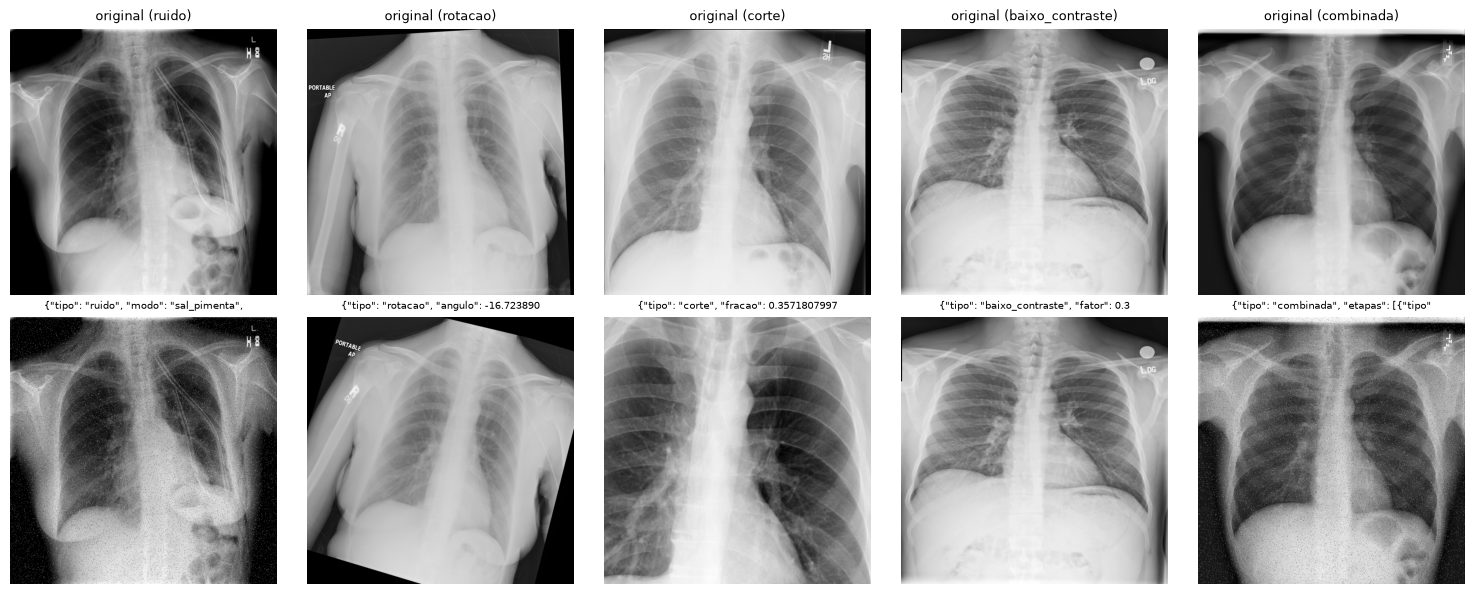

In [4]:
fig, axes = plt.subplots(2, len(DEGRADATIONS), figsize=(3 * len(DEGRADATIONS), 6))
for j, kind in enumerate(DEGRADATIONS):
    row = meta[meta["degradation"] == kind].iloc[0]
    orig = subset[subset["image"] == row["original_image"]].iloc[0]
    axes[0, j].imshow(_read_gray(orig["path"]), cmap="gray"); axes[0, j].set_title(f"original ({kind})", fontsize=9)
    axes[1, j].imshow(_read_gray(row["path"]), cmap="gray"); axes[1, j].set_title(row["params"][:40], fontsize=7)
    for a in axes[:, j]: a.axis("off")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "figures" / "degradado_exemplos.png", dpi=150); plt.show()

## 2. Checagem de qualidade (IMAGEM INADEQUADA)

Limites calibrados nas imagens **originais da validação** (quantil 1%).

In [5]:
val_feats = pd.DataFrame([quality_features(_read_gray(p)) for p in val["path"]])
limits = fit_quality_limits(val_feats)
(RESULTS_DIR / "quality_limits.json").write_text(json.dumps(limits, indent=2), encoding="utf-8")
print(limits)

orig_flags = np.array([is_inadequate(quality_features(_read_gray(p)), limits) for p in subset["path"]])
deg_flags = np.array([is_inadequate(quality_features(_read_gray(p)), limits) for p in meta["path"]])
quality = (pd.DataFrame({"degradation": meta["degradation"], "inadequada": deg_flags})
           .groupby("degradation")["inadequada"].mean().rename("taxa_inadequada_degradada").to_frame())
quality.loc["(originais do teste)"] = orig_flags.mean()
quality.to_csv(RESULTS_DIR / "metrics" / "degraded_quality.csv")
quality

{'contraste': 31.504849764463074, 'nitidez': 18.77655853957749}


,taxa_inadequada_degradada
degradation,
baixo_contraste,1.000000
combinada,0.433333
corte,1.000000
rotacao,0.000000
ruido,0.000000
(originais do teste),0.020000


## 3. Original × degradada com a ResNet-50

Requer `models/resnet50.keras` (gerado no notebook 02; no Colab, copie do Drive para `models/`). Sem o modelo, as células abaixo são ignoradas.

In [6]:
MODEL_PATH = ROOT / "models" / "resnet50.keras"
HAS_MODEL = MODEL_PATH.exists()
print("modelo encontrado:", HAS_MODEL)
if HAS_MODEL:
    import keras
    from src.pipeline import make_dataset
    model = keras.models.load_model(MODEL_PATH)
    prep = keras.applications.resnet50.preprocess_input
    subset["p"] = model.predict(make_dataset(subset, prep, shuffle=False), verbose=0)[:, 0]
    meta["p"] = model.predict(make_dataset(meta, prep, shuffle=False), verbose=0)[:, 0]

modelo encontrado: False


In [7]:
if HAS_MODEL:
    orig_by_name = subset.set_index("image")["p"]
    meta["p_original"] = meta["original_image"].map(orig_by_name)
    rows = []
    for kind in list(DEGRADATIONS) + ["total"]:
        sel = meta if kind == "total" else meta[meta["degradation"] == kind]
        for versao, col in (("original", "p_original"), ("degradada", "p")):
            rows.append({"degradation": kind, "versao": versao,
                         **binary_metrics(sel["label"], sel[col], th.t_rotina)})
    res = pd.DataFrame(rows)
    res.to_csv(RESULTS_DIR / "metrics" / "degraded_by_type.csv", index=False)
    drop = (res.pivot(index="degradation", columns="versao", values=["recall", "f1", "balanced_accuracy"]))
    queda = pd.DataFrame({m: drop[m]["original"] - drop[m]["degradada"] for m in ("recall", "f1", "balanced_accuracy")})
    ax = queda.plot.bar(figsize=(8, 4), title="Queda de desempenho (original − degradada)")
    ax.axhline(0, color="k", lw=0.8); plt.tight_layout()
    plt.savefig(RESULTS_DIR / "figures" / "degradado_queda.png", dpi=150); plt.show()
    res

In [8]:
if HAS_MODEL:
    meta["inadequada"] = deg_flags
    meta["saida"] = decide_many(meta["p"], th, meta["inadequada"])
    prio = pd.crosstab(meta["saida"], meta["degradation"]).reindex(list(OUTPUTS)).fillna(0).astype(int)
    prio.to_csv(RESULTS_DIR / "metrics" / "degraded_priority.csv")
    prio

## Conclusões

- **Checagem de qualidade (contraste e nitidez, limites da validação):** sinaliza 100% do baixo contraste e 100% do corte (a ampliação após o corte borra a imagem e reduz a nitidez), cerca de 43% das combinadas e só 2% das originais do teste. **Não sinaliza rotação nem ruído** (0%): a rotação não altera contraste nem nitidez, e o ruído aumenta a variância do Laplaciano. Essas são limitações conhecidas da checagem.
- **Desempenho original × degradado:** preencher após executar com o modelo `models/resnet50.keras` (células da seção 3).